<a href="https://colab.research.google.com/github/DS-Challenge-Hackathon-J-Group/DataScience-Hackathon/blob/main/RMDS_Data_Science_Hackathon_%E2%80%93_Dataset_B_J_(Group).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# H1N1 Vaccine Uptake Prediction Using Machine Learning

## Project Overview

The objective of this project is to develop machine learning models to predict whether individuals are likely to receive the H1N1 influenza vaccine based on their demographic characteristics, health conditions, opinions, and behavioural factors.

Using the provided H1N1 vaccination dataset, we perform data exploration, data preprocessing, model development, hyperparameter optimisation, and performance evaluation.

Five classification algorithms are implemented and compared:

1. Logistic Regression
2. Random Forest
3. Extra Trees
4. Support Vector Machine (SVM)
5. AdaBoost

The models are evaluated using classification metrics, including accuracy, precision, recall, F1-score, and ROC-AUC, alongside probability evaluation measures such as Brier score and log loss.

We also investigate decision thresholds and estimated costs to identify a potentially cost-effective prediction approach.

Finally, Explainable Artificial Intelligence (XAI) techniques, including SHAP and LIME, are applied to understand the factors influencing model predictions.

## Project Workflow

- Dataset loading and understanding
- Data quality assessment
- Exploratory Data Analysis (EDA)
- Data preprocessing and feature transformation
- Machine learning model development
- Hyperparameter tuning
- Model performance evaluation
- ROC curve comparison
- Cost-based threshold optimisation
- Explainable AI using SHAP and LIME
- Final predictions and submission file generation

## Project Goal

To develop and evaluate machine learning models that can predict H1N1 vaccine uptake while providing interpretable insights into the factors associated with vaccination decisions.


###1. Importing Libraries and Dependencies

This section imports the Python libraries required for the project.

The libraries are used for:
- **Data manipulation:** Pandas and NumPy for loading, cleaning and processing data.
- **Data visualisation:** Matplotlib and Seaborn for creating charts and exploring patterns.
- **Machine learning:** Scikit-learn for preprocessing, model training, hyperparameter tuning and evaluation.
- **Model interpretation:** SHAP and LIME for explaining model predictions.

These libraries provide the tools needed to complete the data analysis and machine learning workflow.


In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns


###2. Loading the Dataset

In this section, we load the training and test datasets into Pandas DataFrames.

The training dataset contains the predictor variables and the target variable, `h1n1_vaccine`, which indicates whether a respondent received the H1N1 vaccine.

The test dataset contains the predictor variables but does not include the target variable. It will be used to generate predictions for the final challenge submissions.

After loading the datasets, we inspect their dimensions, column names and initial records to understand their structure before proceeding with exploratory data analysis.


In [2]:
# Load the training dataset
train_df = pd.read_csv('dataset_B_training.csv')

# Load the testing dataset
test_df = pd.read_csv('dataset_B_testing.csv')

# Load the example submission dataset
submission_df = pd.read_csv('dataset_B_example_submission.csv')


### 3. Verify the datasets

In [3]:
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)
print("Submission dataset:", submission_df.shape)

Training dataset: (4756, 31)
Testing dataset: (4749, 30)
Submission dataset: (4749, 2)


##Understanding the dataset structure

###4. Display column names and data types

In [4]:
# Display all column names and their data types

print("TRAINING DATASET INFORMATION\n")

print(train_df.dtypes)

TRAINING DATASET INFORMATION

respondent_id                      int64
h1n1_concern                     float64
h1n1_knowledge                   float64
behavioral_antiviral_meds        float64
behavioral_avoidance             float64
behavioral_face_mask             float64
behavioral_wash_hands            float64
behavioral_large_gatherings      float64
behavioral_outside_home          float64
behavioral_touch_face            float64
doctor_recc_h1n1                 float64
child_under_6_months             float64
health_worker                    float64
health_insurance                 float64
opinion_h1n1_vacc_effective      float64
opinion_h1n1_risk                float64
opinion_h1n1_sick_from_vacc      float64
age_group                         object
education                         object
race                              object
sex                               object
income_poverty                    object
marital_status                    object
rent_or_own                

### 5. Get a complete dataset summary

In [5]:
# Display dataset information

train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   h1n1_concern                   4741 non-null   float64
 2   h1n1_knowledge                 4734 non-null   float64
 3   behavioral_antiviral_meds      4739 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4752 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4741 non-null   float64
 9   behavioral_touch_face          4736 non-null   float64
 10  doctor_recc_h1n1               4437 non-null   float64
 11  child_under_6_months           4622 non-null   float64
 12  health_worker                  4625 non-null   f

### 6. Display statistical information

In [6]:
# Statistical summary of numerical columns

display(train_df.describe())

,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,child_under_6_months,health_worker,health_insurance,opinion_h1n1_vacc_effective,opinion_h1n1_risk,opinion_h1n1_sick_from_vacc,household_adults,household_children,number_chronic_med_conditions,h1n1_vaccine
count,4756.00000,4741.000000,4734.000000,4739.000000,4729.000000,4752.000000,4748.000000,4747.000000,4741.000000,4736.000000,...,4622.000000,4625.000000,2831.000000,4687.000000,4692.000000,4692.000000,4722.000000,4722.000000,4756.000000,4756.000000
mean,2378.50000,1.658933,1.307140,0.057396,0.740960,0.077652,0.842039,0.359385,0.341278,0.704814,...,0.090437,0.141189,0.901801,3.965436,2.512361,2.412191,0.888818,0.542143,0.391295,0.394029
std,1373.08327,0.892478,0.612811,0.232622,0.438154,0.267651,0.364743,0.479871,0.474189,0.456174,...,0.286838,0.348254,0.297635,0.981737,1.336426,1.372509,0.755777,0.931243,0.677845,0.488692
min,1.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,1189.75000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,4.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
50%,2378.50000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,1.000000,4.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000
75%,3567.25000,2.000000,2.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,1.000000,5.000000,4.000000,4.000000,1.000000,1.000000,1.000000,1.000000
max,4756.00000,3.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,5.000000,5.000000,5.000000,3.000000,3.000000,6.000000,1.000000


## Data Quality Assessment

### 7. Check missing values


In [7]:
# Calculate missing values in each column

missing_values = train_df.isnull().sum()

# Calculate missing percentage

missing_percentage = (train_df.isnull().mean() * 100)

# Create a summary table

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage (%)': missing_percentage
})

# Display columns containing missing values

missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Missing Percentage (%)', ascending=False)

display(missing_summary.round(2))

,Missing Values,Missing Percentage (%)
employment_sector,2364,49.71
health_insurance,1925,40.48
income_poverty,712,14.97
doctor_recc_h1n1,319,6.71
rent_or_own,315,6.62
employment_status,235,4.94
marital_status,226,4.75
education,224,4.71
child_under_6_months,134,2.82
health_worker,131,2.75


### 8. Check duplicate records

In [8]:
# Check duplicate rows

print("Duplicate rows in training dataset:",
      train_df.duplicated().sum())

print("Duplicate rows in testing dataset:",
      test_df.duplicated().sum())

Duplicate rows in training dataset: 0
Duplicate rows in testing dataset: 0


### 9. Check duplicate respondent IDs

In [9]:
# Check duplicate respondent identifiers

print("Duplicate IDs in training dataset:",
      train_df['respondent_id'].duplicated().sum())

print("Duplicate IDs in testing dataset:",
      test_df['respondent_id'].duplicated().sum())

Duplicate IDs in training dataset: 0
Duplicate IDs in testing dataset: 0


### 10. Check training and testing ID overlap

In [10]:
# Identify IDs appearing in both datasets

common_ids = set(train_df['respondent_id']).intersection(
    set(test_df['respondent_id'])
)

print("Number of overlapping respondent IDs:", len(common_ids))

Number of overlapping respondent IDs: 0


## Missing-value visualisation

### 11. Visualise missing-value percentages

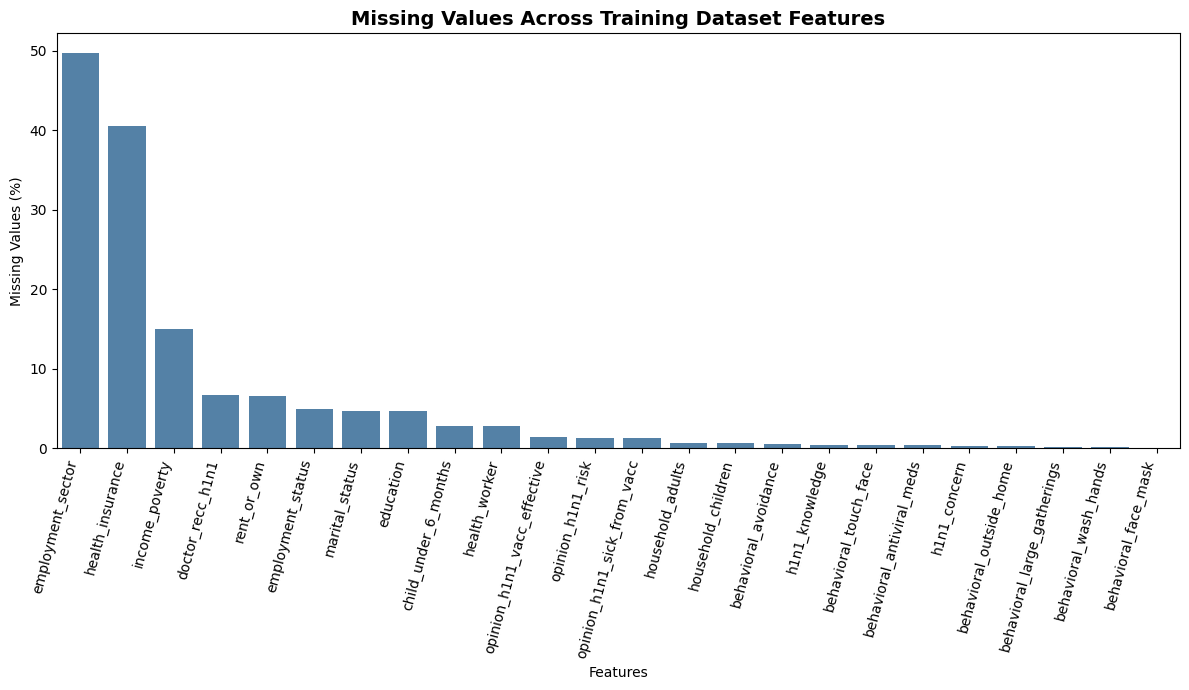

In [11]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.barplot(
    x=missing_summary.index,
    y=missing_summary['Missing Percentage (%)'],
    color='steelblue'
)

plt.title('Missing Values Across Training Dataset Features',
          fontsize=14, fontweight='bold')

plt.xlabel('Features')
plt.ylabel('Missing Values (%)')

plt.xticks(rotation=75, ha='right')

plt.tight_layout()
plt.show()


##Exploratory Data Analysis (EDA)
##EDA 1: Target Variable Analysis

Exploratory Data Analysis is performed to understand the characteristics of the respondents and identify patterns in the dataset.

The analysis includes:

- Distribution of the target variable.
- Distributions of numerical and ordinal variables.
- Distributions of categorical variables.
- Missing-value patterns.
- Correlations between numerical and ordinal variables.

Visualisations are used to identify possible relationships between respondent characteristics and vaccine acceptance.

EDA helps inform preprocessing and model development decisions.

### 12. Analyse vaccination distribution

In [12]:
# Calculate vaccination counts
target_counts = train_df['h1n1_vaccine'].value_counts()

# Calculate vaccination percentages
target_percentages = (
    train_df['h1n1_vaccine'].value_counts(normalize=True) * 100
)

print("Vaccination Counts:")
print(target_counts)

print("\nVaccination Percentages:")
print(target_percentages.round(2))

Vaccination Counts:
h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64

Vaccination Percentages:
h1n1_vaccine
0    60.6
1    39.4
Name: proportion, dtype: float64


### 13. Visualise vaccination distribution

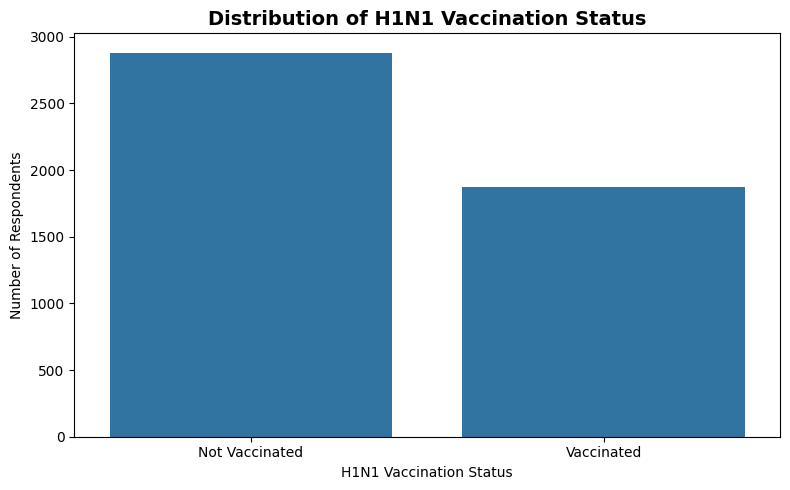

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x='h1n1_vaccine'
)

plt.title('Distribution of H1N1 Vaccination Status',
          fontsize=14, fontweight='bold')

plt.xlabel('H1N1 Vaccination Status')
plt.ylabel('Number of Respondents')

plt.xticks([0, 1], ['Not Vaccinated', 'Vaccinated'])

plt.tight_layout()
plt.show()

##EDA 2: Numerical and ordinal feature analysis

### 14. Identify numerical and ordinal features

In [14]:
# Numerical and ordinal features

numerical_features = [
    'h1n1_concern',
    'h1n1_knowledge',
    'opinion_h1n1_vacc_effective',
    'opinion_h1n1_risk',
    'opinion_h1n1_sick_from_vacc',
    'household_adults',
    'household_children',
    'number_chronic_med_conditions'
]

print("Number of numerical and ordinal features:",
      len(numerical_features))

print("\nSelected features:")
for feature in numerical_features:
    print(feature)

Number of numerical and ordinal features: 8

Selected features:
h1n1_concern
h1n1_knowledge
opinion_h1n1_vacc_effective
opinion_h1n1_risk
opinion_h1n1_sick_from_vacc
household_adults
household_children
number_chronic_med_conditions


### 15. Identify categorical features

In [15]:

# Identify categorical features

categorical_features = train_df.select_dtypes(
    include=['object']
).columns.tolist()

print("Number of categorical features:",
      len(categorical_features))

print("\nCategorical features:")

for feature in categorical_features:
    print(feature)


Number of categorical features: 10

Categorical features:
age_group
education
race
sex
income_poverty
marital_status
rent_or_own
employment_status
census_msa
employment_sector


### 16. Visualise categorical feature distributions

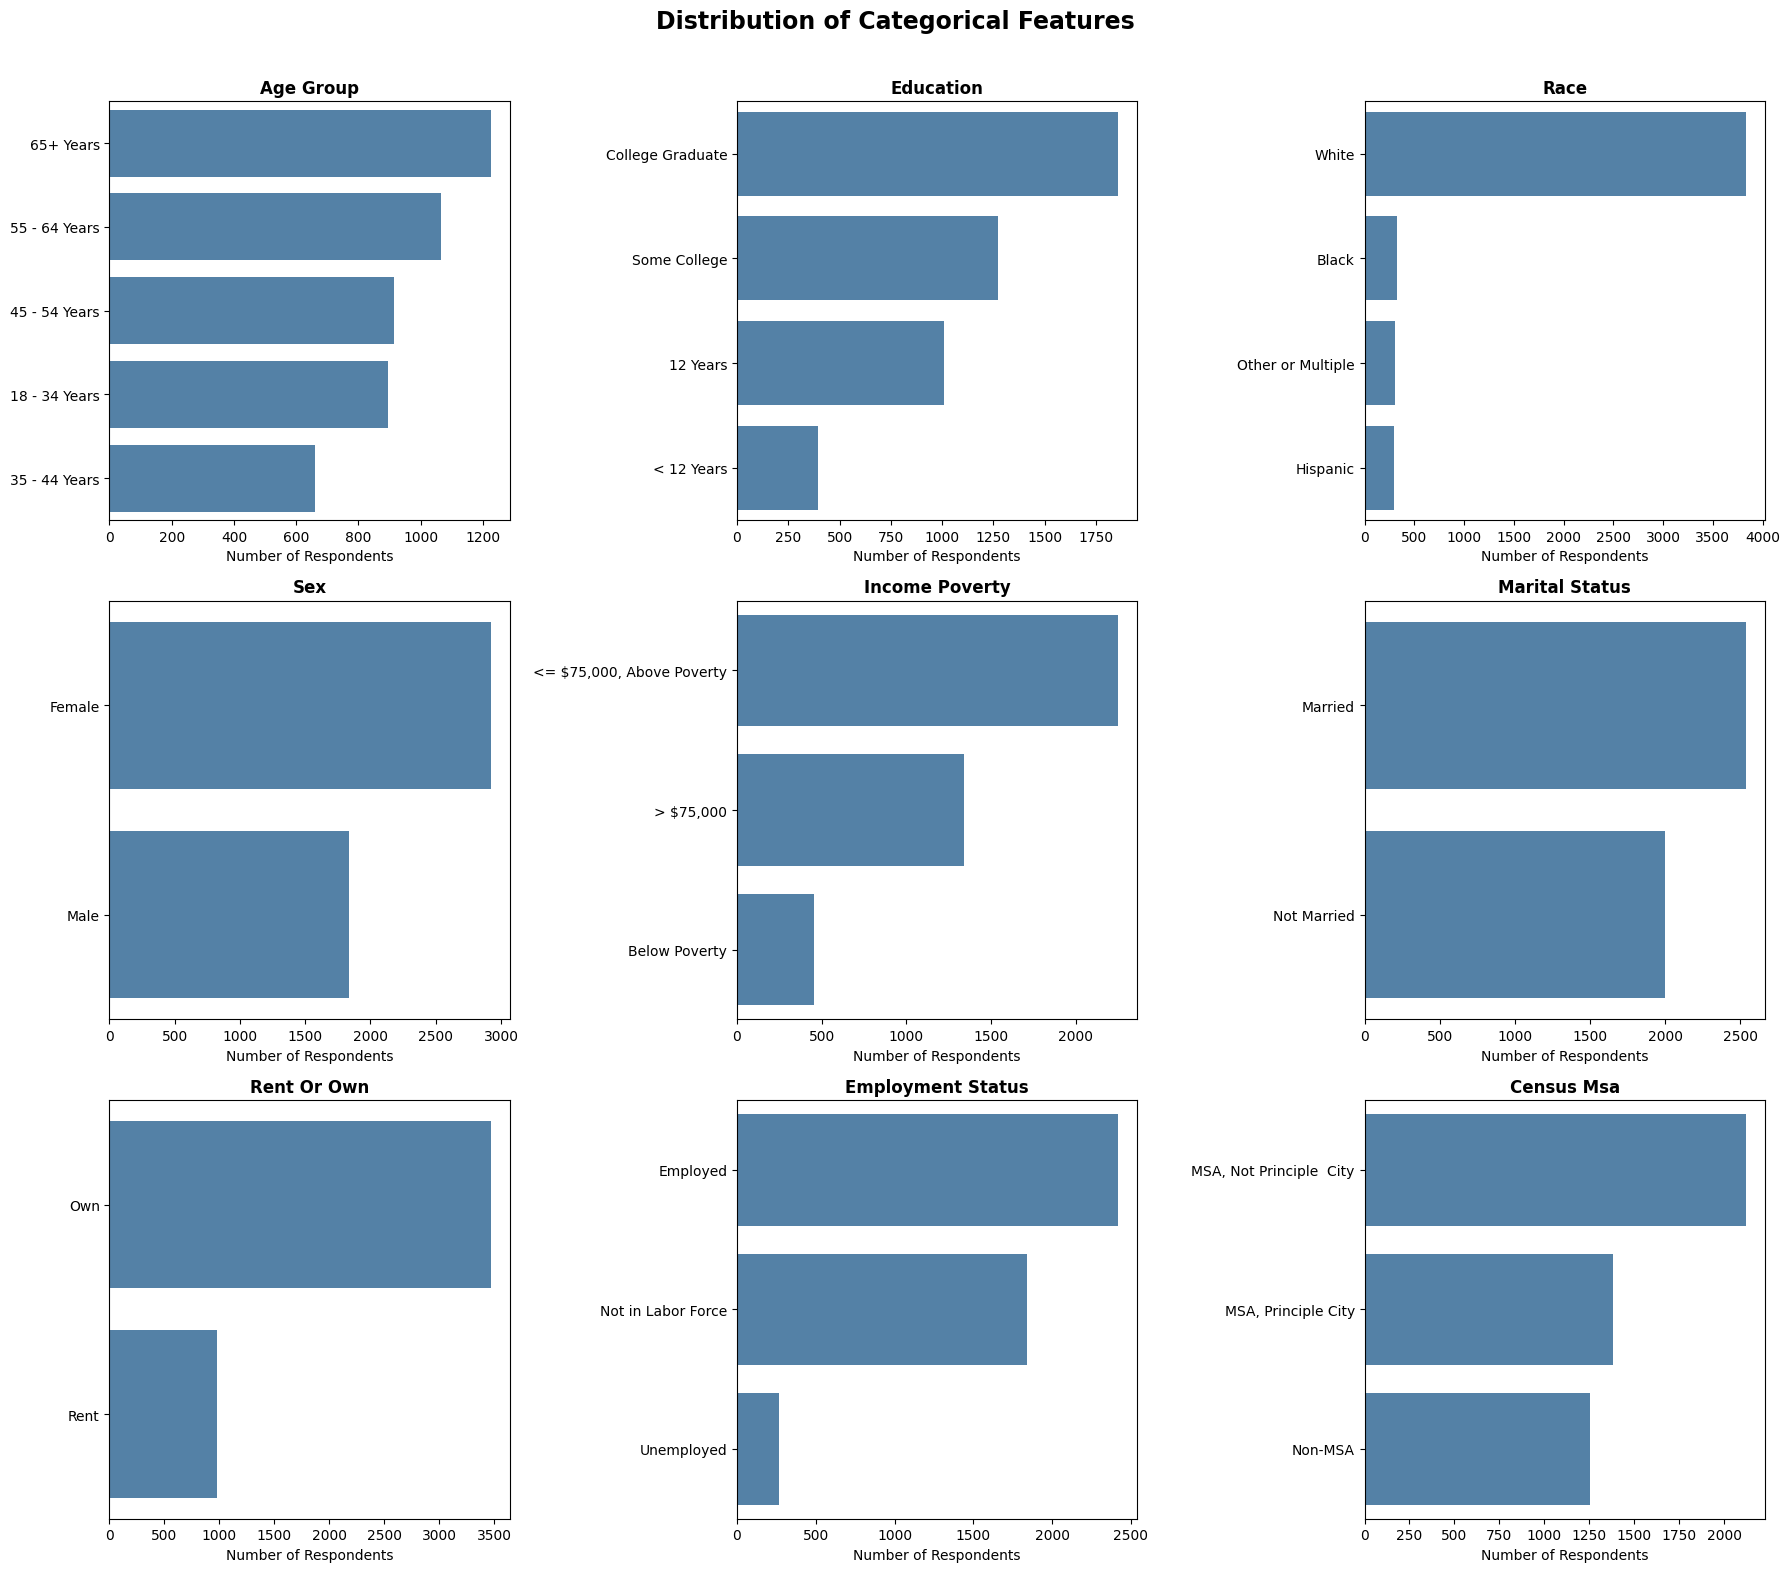

In [16]:

# Select categorical features except employment_sector
categorical_plot_features = [
    feature for feature in categorical_features
    if feature != 'employment_sector'
]

# Create subplot grid
fig, axes = plt.subplots(3, 3, figsize=(18, 16))

axes = axes.flatten()

for i, feature in enumerate(categorical_plot_features):

    order = train_df[feature].value_counts().index

    sns.countplot(
        data=train_df,
        y=feature,
        order=order,
        ax=axes[i],
        color='steelblue'
    )

    axes[i].set_title(
        feature.replace('_', ' ').title(),
        fontsize=12,
        fontweight='bold'
    )

    axes[i].set_xlabel('Number of Respondents')
    axes[i].set_ylabel('')

plt.suptitle(
    'Distribution of Categorical Features',
    fontsize=17,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


##EDA 3.1 — Employment sector analysis

### 17. Employment sector distribution

Employment Sector Distribution:


,Number of Respondents
employment_sector,
Missing,2364
healthcare,546
science,320
wholesale,211
education,179
construction,168
agriculture,162
utilities,120
finance,96


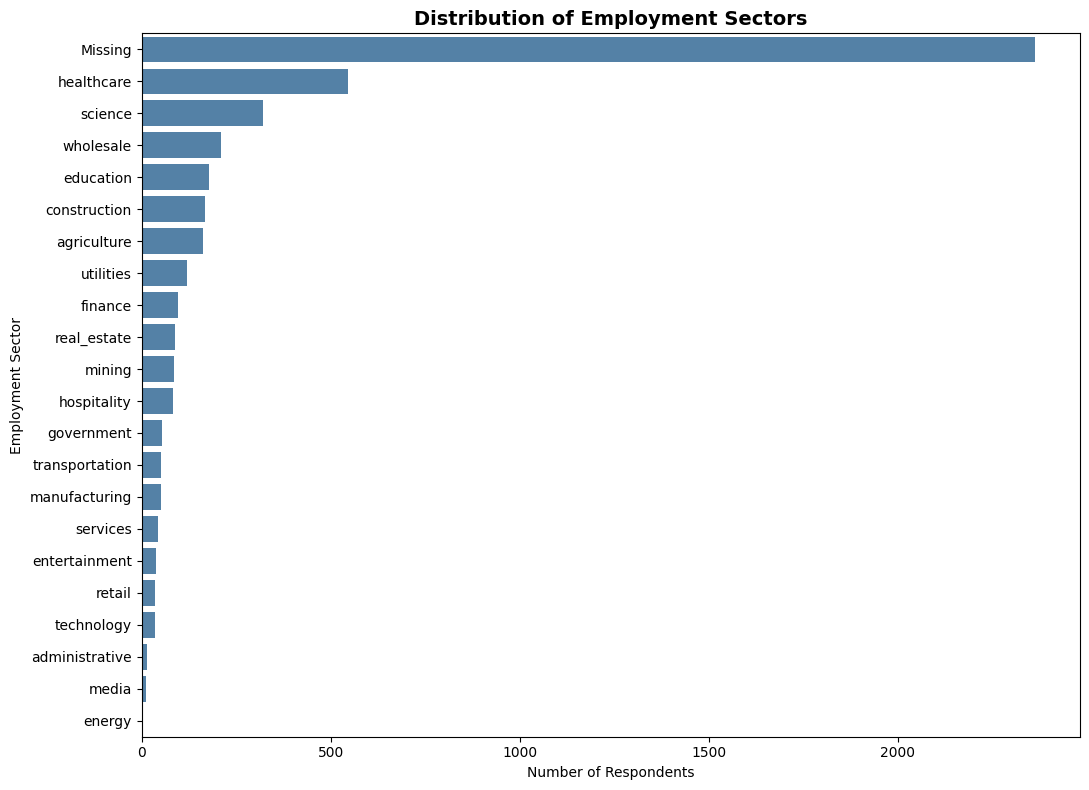

In [17]:

# Create a temporary copy for visualisation
employment_sector_data = (
    train_df['employment_sector']
    .fillna('Missing')
)

# Calculate category frequencies
sector_counts = employment_sector_data.value_counts()

# Display category frequencies
print("Employment Sector Distribution:")
display(sector_counts.to_frame(name='Number of Respondents'))

# Visualise employment sectors
plt.figure(figsize=(11, 8))

sns.countplot(
    y=employment_sector_data,
    order=sector_counts.index,
    color='steelblue'
)

plt.title(
    'Distribution of Employment Sectors',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Number of Respondents')
plt.ylabel('Employment Sector')

plt.tight_layout()
plt.show()


### 18. Correlation Heatmap

### Calculate and visualise correlations

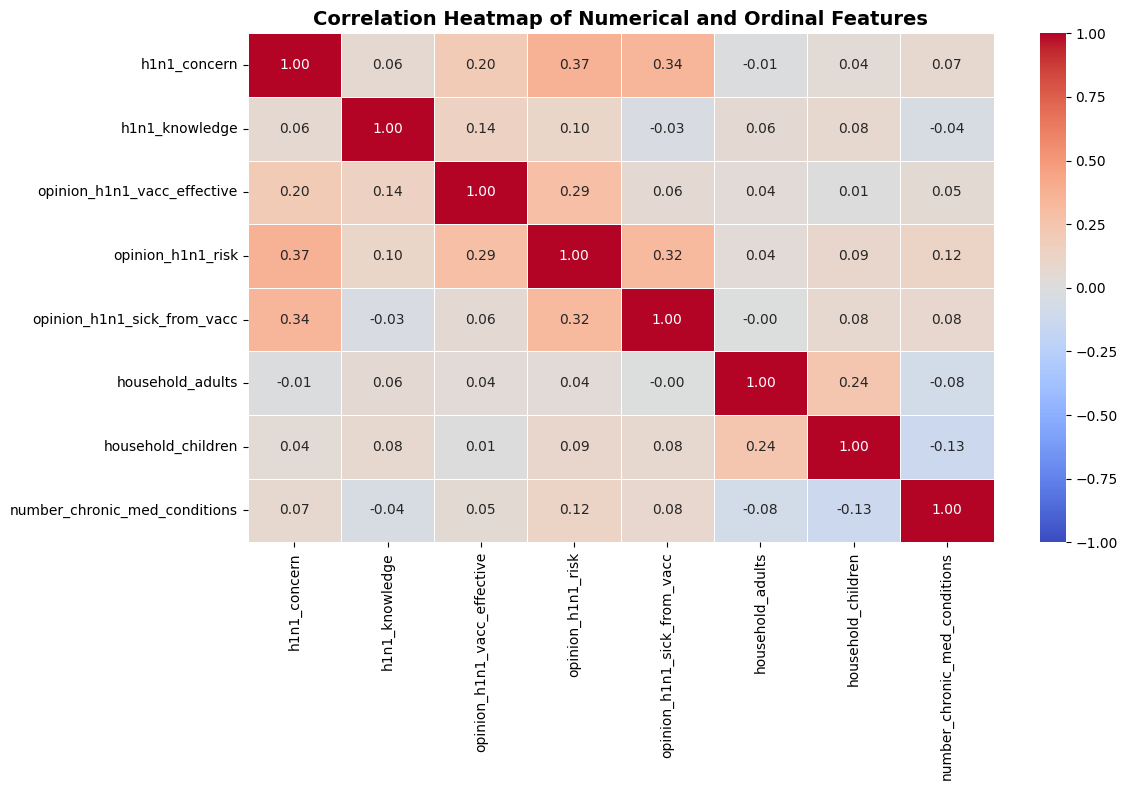

In [18]:

# Select numerical and ordinal features
correlation_features = numerical_features

# Calculate correlation matrix
correlation_matrix = train_df[correlation_features].corr(method='spearman')

# Plot correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title(
    'Correlation Heatmap of Numerical and Ordinal Features',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


## Data Preprocessing

### 19. Separate Features and Target Variable

The target variable is `h1n1_vaccine`, which indicates whether a respondent accepts the H1N1 vaccine.

The `respondent_id` column is excluded from the predictor variables because it is an identifier rather than a meaningful predictive feature.

The remaining 29 columns are used as input features.

The data is separated into:
- X: predictor variables.
- y: target variable.

The testing dataset is prepared using the same predictor columns.

In [19]:


# Separate independent variables and target variable
X = train_df.drop(columns=['h1n1_vaccine', 'respondent_id'])

y = train_df['h1n1_vaccine']

# Prepare testing features
X_test = test_df.drop(columns=['respondent_id'])

# Preserve respondent IDs for final submission
test_ids = test_df['respondent_id'].copy()


### 20. Verify the separation

In [20]:

print("Training Features (X):", X.shape)
print("Target Variable (y):", y.shape)
print("Testing Features (X_test):", X_test.shape)

print("\nTarget Variable Distribution:")
print(y.value_counts())

print("\nMissing values in target:", y.isnull().sum())


Training Features (X): (4756, 29)
Target Variable (y): (4756,)
Testing Features (X_test): (4749, 29)

Target Variable Distribution:
h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64

Missing values in target: 0


### 21. Identify feature types

In [21]:

# ==========================================
# CELL 22: IDENTIFY FEATURE TYPES
# ==========================================

# Binary features (0 = No, 1 = Yes)
binary_features = [
    'behavioral_antiviral_meds',
    'behavioral_avoidance',
    'behavioral_face_mask',
    'behavioral_wash_hands',
    'behavioral_large_gatherings',
    'behavioral_outside_home',
    'behavioral_touch_face',
    'doctor_recc_h1n1',
    'child_under_6_months',
    'health_worker',
    'health_insurance'
]

# Numerical and ordinal features
numerical_features = [
    'h1n1_concern',
    'h1n1_knowledge',
    'opinion_h1n1_vacc_effective',
    'opinion_h1n1_risk',
    'opinion_h1n1_sick_from_vacc',
    'household_adults',
    'household_children',
    'number_chronic_med_conditions'
]

# Categorical features
categorical_features = [
    'age_group',
    'education',
    'race',
    'sex',
    'income_poverty',
    'marital_status',
    'rent_or_own',
    'employment_status',
    'census_msa',
    'employment_sector'
]

print("Binary features:", len(binary_features))
print("Numerical and ordinal features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nTotal features:",
      len(binary_features) +
      len(numerical_features) +
      len(categorical_features))


Binary features: 11
Numerical and ordinal features: 8
Categorical features: 10

Total features: 29


### 22. Verify feature classification


The predictor variables are divided into three groups to support appropriate preprocessing:

1. Binary features: variables representing yes/no responses.
2. Numerical and ordinal features: variables representing quantities or ordered response levels.
3. Categorical features: variables representing demographic and employment categories.

Each group requires different preprocessing techniques to ensure that the information is suitable for machine learning algorithms.

In [22]:

# Combine all feature groups
all_features = (
    binary_features +
    numerical_features +
    categorical_features
)

# Check for missing or duplicated feature assignments
print("Total features in X:", len(X.columns))
print("Total classified features:", len(all_features))

print("Duplicate assignments:",
      len(all_features) - len(set(all_features)))

print("Unclassified features:",
      set(X.columns) - set(all_features))

print("Unexpected features:",
      set(all_features) - set(X.columns))


Total features in X: 29
Total classified features: 29
Duplicate assignments: 0
Unclassified features: set()
Unexpected features: set()


### 23. Build the preprocessing pipeline



Import preprocessing tools

In [23]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

### 24. Create preprocessing pipeline

In [24]:
# Numerical and ordinal preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Binary preprocessing
binary_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine all preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('bin', binary_transformer, binary_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)


### 25. Split the training data

Training and Validation Split

The training dataset is divided into training and validation subsets using an 80:20 split.

Stratified sampling is applied to preserve the proportion of vaccine acceptance and non-acceptance in both subsets.

A fixed random state is used to ensure reproducibility.

The validation dataset is used to compare model performance and optimise classification thresholds without using the testing dataset.

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True).round(3))

Training features: (3804, 29)
Validation features: (952, 29)

Training target distribution:
h1n1_vaccine
0    0.606
1    0.394
Name: proportion, dtype: float64

Validation target distribution:
h1n1_vaccine
0    0.606
1    0.394
Name: proportion, dtype: float64


 Baseline Machine Learning Models

Five classification algorithms are developed and evaluated:

1. Logistic Regression.
2. Random Forest.
3. Extra Trees.
4. Support Vector Machine (SVM).
5. AdaBoost.

Each algorithm is combined with the preprocessing pipeline.

Baseline models are trained using the training subset and evaluated using the validation subset.

The purpose is to establish initial performance results before hyperparameter optimisation.

### 26. Train our first model: Logistic Regression

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)

y_val_pred = logistic_model.predict(X_val)
y_val_proba = logistic_model.predict_proba(X_val)[:, 1]

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_pred), 4))
print("Recall:", round(recall_score(y_val, y_val_pred), 4))
print("F1-score:", round(f1_score(y_val, y_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_proba), 4))

Logistic Regression Results
---------------------------
Accuracy: 0.7584
Precision: 0.7259
Recall: 0.6213
F1-score: 0.6695
ROC-AUC: 0.8165


### 27. Train our second model: Random Forest

In [27]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

rf_val_pred = random_forest_model.predict(X_val)
rf_val_proba = random_forest_model.predict_proba(X_val)[:, 1]

print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_val, rf_val_pred), 4))
print("Precision:", round(precision_score(y_val, rf_val_pred), 4))
print("Recall:", round(recall_score(y_val, rf_val_pred), 4))
print("F1-score:", round(f1_score(y_val, rf_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, rf_val_proba), 4))

Random Forest Results
---------------------
Accuracy: 0.7479
Precision: 0.7077
Recall: 0.6133
F1-score: 0.6571
ROC-AUC: 0.7936


### 28. Train Extra ( extremely Randomised Trees )



In [28]:
from sklearn.ensemble import ExtraTreesClassifier

extra_trees_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

extra_trees_model.fit(X_train, y_train)

et_val_pred = extra_trees_model.predict(X_val)
et_val_proba = extra_trees_model.predict_proba(X_val)[:, 1]

print("Extra Trees Results")
print("-------------------")
print("Accuracy:", round(accuracy_score(y_val, et_val_pred), 4))
print("Precision:", round(precision_score(y_val, et_val_pred), 4))
print("Recall:", round(recall_score(y_val, et_val_pred), 4))
print("F1-score:", round(f1_score(y_val, et_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, et_val_proba), 4))

Extra Trees Results
-------------------
Accuracy: 0.7616
Precision: 0.7312
Recall: 0.624
F1-score: 0.6734
ROC-AUC: 0.7963


### 29. Train Support Vector Machine (SVM)

In [29]:
from sklearn.svm import SVC

svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(
        kernel='rbf',
        C=1.0,
        probability=True,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

svm_val_pred = svm_model.predict(X_val)
svm_val_proba = svm_model.predict_proba(X_val)[:, 1]

print("SVM Results")
print("-----------")
print("Accuracy:", round(accuracy_score(y_val, svm_val_pred), 4))
print("Precision:", round(precision_score(y_val, svm_val_pred), 4))
print("Recall:", round(recall_score(y_val, svm_val_pred), 4))
print("F1-score:", round(f1_score(y_val, svm_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, svm_val_proba), 4))

SVM Results
-----------
Accuracy: 0.7563
Precision: 0.72
Recall: 0.624
F1-score: 0.6686
ROC-AUC: 0.8019


### 30. Train AdaBoost

In [30]:
from sklearn.ensemble import AdaBoostClassifier

adaboost_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ))
])

adaboost_model.fit(X_train, y_train)

ada_val_pred = adaboost_model.predict(X_val)
ada_val_proba = adaboost_model.predict_proba(X_val)[:, 1]

print("AdaBoost Results")
print("----------------")
print("Accuracy:", round(accuracy_score(y_val, ada_val_pred), 4))
print("Precision:", round(precision_score(y_val, ada_val_pred), 4))
print("Recall:", round(recall_score(y_val, ada_val_pred), 4))
print("F1-score:", round(f1_score(y_val, ada_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, ada_val_proba), 4))

AdaBoost Results
----------------
Accuracy: 0.7553
Precision: 0.7233
Recall: 0.6133
F1-score: 0.6638
ROC-AUC: 0.8078


### 31. Update the comparison table

###  Baseline Model Evaluation

The baseline models are evaluated using several classification metrics:

- Accuracy: proportion of correct predictions.
- Precision: proportion of predicted vaccine accepters who actually accept.
- Recall: proportion of actual vaccine accepters correctly identified.
- F1-score: harmonic mean of precision and recall.
- ROC-AUC: ability of the model to distinguish between the two classes.
- Confusion matrix: breakdown of true positives, false positives, true negatives and false negatives.

Brier score and log loss are also considered to evaluate the quality of predicted probabilities.

These metrics provide a broader assessment than accuracy alone.

In [31]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Extra Trees',
        'SVM',
        'AdaBoost'
    ],
    'Accuracy': [
        accuracy_score(y_val, y_val_pred),
        accuracy_score(y_val, rf_val_pred),
        accuracy_score(y_val, et_val_pred),
        accuracy_score(y_val, svm_val_pred),
        accuracy_score(y_val, ada_val_pred)
    ],
    'Precision': [
        precision_score(y_val, y_val_pred),
        precision_score(y_val, rf_val_pred),
        precision_score(y_val, et_val_pred),
        precision_score(y_val, svm_val_pred),
        precision_score(y_val, ada_val_pred)
    ],
    'Recall': [
        recall_score(y_val, y_val_pred),
        recall_score(y_val, rf_val_pred),
        recall_score(y_val, et_val_pred),
        recall_score(y_val, svm_val_pred),
        recall_score(y_val, ada_val_pred)
    ],
    'F1-score': [
        f1_score(y_val, y_val_pred),
        f1_score(y_val, rf_val_pred),
        f1_score(y_val, et_val_pred),
        f1_score(y_val, svm_val_pred),
        f1_score(y_val, ada_val_pred)
    ],
    'ROC-AUC': [
        roc_auc_score(y_val, y_val_proba),
        roc_auc_score(y_val, rf_val_proba),
        roc_auc_score(y_val, et_val_proba),
        roc_auc_score(y_val, svm_val_proba),
        roc_auc_score(y_val, ada_val_proba)
    ]
})

print(results.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression    0.7584     0.7259  0.6213    0.6695   0.8165
      Random Forest    0.7479     0.7077  0.6133    0.6571   0.7936
        Extra Trees    0.7616     0.7312  0.6240    0.6734   0.7963
                SVM    0.7563     0.7200  0.6240    0.6686   0.8019
           AdaBoost    0.7553     0.7233  0.6133    0.6638   0.8078


### 32. Update probability comparison

In [32]:
probability_comparison = pd.DataFrame({
    'Actual': y_val.values,
    'Logistic Regression': y_val_proba,
    'Random Forest': rf_val_proba,
    'Extra Trees': et_val_proba,
    'SVM': svm_val_proba,
    'AdaBoost': ada_val_proba
})

print(probability_comparison.head(10).round(3))

print("\nAverage predicted vaccination probabilities:")
print(
    probability_comparison.drop(columns='Actual')
    .mean()
    .round(4)
)

   Actual  Logistic Regression  Random Forest  Extra Trees    SVM  AdaBoost
0       0                0.317          0.617        0.683  0.316     0.410
1       0                0.582          0.477        0.430  0.591     0.442
2       0                0.082          0.160        0.197  0.098     0.249
3       0                0.108          0.123        0.160  0.082     0.259
4       0                0.045          0.123        0.110  0.079     0.248
5       0                0.172          0.097        0.110  0.104     0.270
6       0                0.110          0.063        0.083  0.138     0.273
7       0                0.337          0.340        0.280  0.314     0.444
8       1                0.613          0.567        0.537  0.675     0.583
9       0                0.049          0.043        0.050  0.055     0.238

Average predicted vaccination probabilities:
Logistic Regression    0.3962
Random Forest          0.4011
Extra Trees            0.4021
SVM                    0.399

### 33. Probability quality for all five models

In [33]:
from sklearn.metrics import brier_score_loss, log_loss

probability_scores = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Extra Trees',
        'SVM',
        'AdaBoost'
    ],
    'Brier Score': [
        brier_score_loss(y_val, y_val_proba),
        brier_score_loss(y_val, rf_val_proba),
        brier_score_loss(y_val, et_val_proba),
        brier_score_loss(y_val, svm_val_proba),
        brier_score_loss(y_val, ada_val_proba)
    ],
    'Log Loss': [
        log_loss(y_val, y_val_proba),
        log_loss(y_val, rf_val_proba),
        log_loss(y_val, et_val_proba),
        log_loss(y_val, svm_val_proba),
        log_loss(y_val, ada_val_proba)
    ]
})

print(probability_scores.round(4).to_string(index=False))

              Model  Brier Score  Log Loss
Logistic Regression       0.1671    0.5062
      Random Forest       0.1770    0.5345
        Extra Trees       0.1760    0.5356
                SVM       0.1732    0.5231
           AdaBoost       0.1838    0.5531


### 34. Import tuning tools

 Hyperparameter Optimisation

RandomizedSearchCV is used to identify suitable hyperparameters for each classification algorithm.

Stratified cross-validation is applied to maintain class proportions across the folds.

ROC-AUC is used as the scoring metric during the initial tuning process.

The best-performing estimator for each algorithm is retained for further evaluation.

Hyperparameter tuning aims to improve model generalisation and predictive performance.

In [34]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import loguniform, randint

### 35. Tune all five models

In [35]:
param_distributions = {
    'Logistic Regression': {
        'classifier__C': loguniform(0.01, 100)
    },
    'Random Forest': {
        'classifier__n_estimators': randint(150, 401),
        'classifier__max_depth': [None, 5, 10, 15, 20],
        'classifier__min_samples_leaf': randint(1, 6),
        'classifier__max_features': ['sqrt', 'log2']
    },
    'Extra Trees': {
        'classifier__n_estimators': randint(150, 401),
        'classifier__max_depth': [None, 5, 10, 15, 20],
        'classifier__min_samples_leaf': randint(1, 6),
        'classifier__max_features': ['sqrt', 'log2']
    },
    'SVM': {
        'classifier__C': loguniform(0.01, 100),
        'classifier__gamma': ['scale', 'auto']
    },
    'AdaBoost': {
        'classifier__n_estimators': randint(50, 201),
        'classifier__learning_rate': loguniform(0.01, 1)
    }
}

base_models = {
    'Logistic Regression': logistic_model,
    'Random Forest': random_forest_model,
    'Extra Trees': extra_trees_model,
    'SVM': svm_model,
    'AdaBoost': adaboost_model
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

tuned_models = {}
tuning_results = []

for name, model in base_models.items():
    print("Tuning:", name)

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_distributions[name],
        n_iter=6,
        scoring='roc_auc',
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        'Model': name,
        'Best CV ROC-AUC': search.best_score_,
        'Best Parameters': search.best_params_
    })

tuning_table = pd.DataFrame(tuning_results)

print("\nTuning results:")
print(tuning_table.to_string(index=False))

Tuning: Logistic Regression
Tuning: Random Forest
Tuning: Extra Trees
Tuning: SVM
Tuning: AdaBoost

Tuning results:
              Model  Best CV ROC-AUC                                                                                                                       Best Parameters
Logistic Regression         0.823872                                                                                                {'classifier__C': 0.04207988669606638}
      Random Forest         0.825653 {'classifier__max_depth': 10, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 249}
        Extra Trees         0.820907 {'classifier__max_depth': 15, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 221}
                SVM         0.826345                                                                   {'classifier__C': 0.6071989493441299, 'classifier__gamma': 'scale'}
           AdaBoost         0

###  Evaluation of Tuned Models

The tuned models are evaluated on the same validation dataset used for baseline comparison.

Their accuracy, precision, recall, F1-score, ROC-AUC, Brier score and log loss are compared.

The results help determine whether hyperparameter optimisation improved each model and identify the strongest candidates for subsequent cost analysis.

The best model based on classification performance is not automatically assumed to be the best model for cost minimisation.

### 36. Evaluate all five tuned models

In [36]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, brier_score_loss, log_loss

tuned_predictions = {}
tuned_probabilities = {}
tuned_results = []

for name, model in tuned_models.items():

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    tuned_predictions[name] = predictions
    tuned_probabilities[name] = probabilities

    tuned_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision': precision_score(y_val, predictions),
        'Recall': recall_score(y_val, predictions),
        'F1-score': f1_score(y_val, predictions),
        'ROC-AUC': roc_auc_score(y_val, probabilities),
        'Brier Score': brier_score_loss(y_val, probabilities),
        'Log Loss': log_loss(y_val, probabilities)
    })

tuned_comparison = pd.DataFrame(tuned_results)

print(tuned_comparison.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC  Brier Score  Log Loss
Logistic Regression    0.7542     0.7252  0.6053    0.6599   0.8118       0.1690    0.5107
      Random Forest    0.7521     0.7340  0.5813    0.6488   0.8010       0.1757    0.5312
        Extra Trees    0.7710     0.7540  0.6213    0.6813   0.8068       0.1723    0.5237
                SVM    0.7584     0.7273  0.6187    0.6686   0.8020       0.1732    0.5234
           AdaBoost    0.7500     0.7121  0.6133    0.6590   0.8032       0.1776    0.5365


### ROC Curve Comparison of Tuned Models

The Receiver Operating Characteristic (ROC) curve evaluates the ability of a classification model to distinguish between the positive and negative classes across different classification thresholds.

The curve plots:

- True Positive Rate (Sensitivity) on the y-axis.
- False Positive Rate (1 - Specificity) on the x-axis.

The Area Under the ROC Curve (ROC-AUC) provides a single measure of model discrimination. A higher ROC-AUC indicates better ability to distinguish between respondents who accept and do not accept the H1N1 vaccine.

ROC curves are plotted for all five tuned models to compare their classification performance.

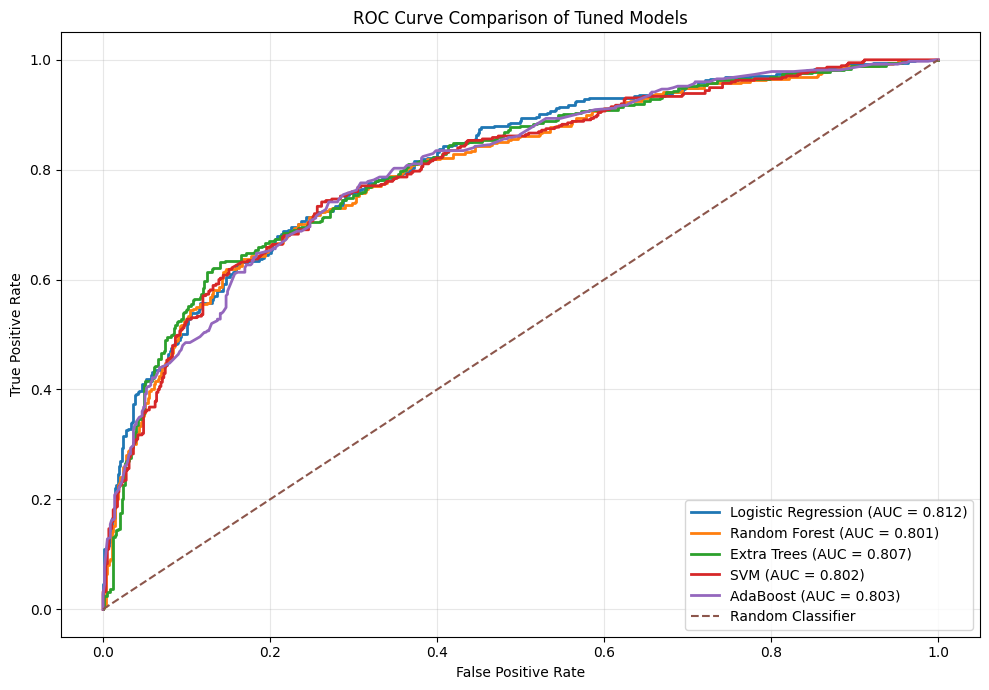

In [37]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for model_name, probabilities in tuned_probabilities.items():

    fpr, tpr, thresholds_roc = roc_curve(
        y_val,
        probabilities
    )

    auc_score = roc_auc_score(y_val, probabilities)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Tuned Models")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 37. Optimise the decision threshold for all five models

In [38]:
import numpy as np
from sklearn.metrics import confusion_matrix

thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for name, probabilities in tuned_probabilities.items():

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        vaccine_cost = (fp + fn) * 500

        threshold_results.append({
            'Model': name,
            'Threshold': round(threshold, 2),
            'FP': fp,
            'FN': fn,
            'TP': tp,
            'TN': tn,
            'Vaccine Mismatch Cost ($)': vaccine_cost
        })

threshold_table = pd.DataFrame(threshold_results)

best_vaccine_thresholds = (
    threshold_table
    .sort_values('Vaccine Mismatch Cost ($)')
    .groupby('Model')
    .first()
    .reset_index()
)

print("Best vaccine allocation threshold for each model:")
print(best_vaccine_thresholds.to_string(index=False))

Best vaccine allocation threshold for each model:
              Model  Threshold  FP  FN  TP  TN  Vaccine Mismatch Cost ($)
           AdaBoost       0.50  93 145 230 484                     119000
        Extra Trees       0.50  76 142 233 501                     109000
Logistic Regression       0.50  86 148 227 491                     117000
      Random Forest       0.55  56 178 197 521                     117000
                SVM       0.55  76 155 220 501                     115500


### 38. Calculate and rank vaccine costs

### Classification Threshold Optimisation

The default classification threshold of 0.50 is not necessarily the most suitable decision threshold for this challenge.

Different thresholds are tested using the predicted validation probabilities.

For each threshold, the number of true positives, false positives, false negatives and true negatives is calculated.

The initial vaccine mismatch cost is calculated using the false-positive and false-negative counts, with a vaccine cost of $500 per mismatch.

This analysis illustrates how changing the classification threshold affects vaccine allocation and the estimated vaccine-related costs.

The initial mismatch-cost calculation is kept separate from the subsequent combined-cost analysis.

In [39]:
best_vaccine_thresholds['Cost per Respondent ($)'] = (
    best_vaccine_thresholds['Vaccine Mismatch Cost ($)'] / len(y_val)
)

best_vaccine_thresholds = best_vaccine_thresholds.sort_values(
    'Vaccine Mismatch Cost ($)'
)

print(best_vaccine_thresholds[
    ['Model', 'Threshold', 'FP', 'FN',
     'Vaccine Mismatch Cost ($)', 'Cost per Respondent ($)']
].round(2).to_string(index=False))

              Model  Threshold  FP  FN  Vaccine Mismatch Cost ($)  Cost per Respondent ($)
        Extra Trees       0.50  76 142                     109000                   114.50
                SVM       0.55  76 155                     115500                   121.32
      Random Forest       0.55  56 178                     117000                   122.90
Logistic Regression       0.50  86 148                     117000                   122.90
           AdaBoost       0.50  93 145                     119000                   125.00


### 39. calculate combined expected costs

### Combined Vaccine and Hospitalisation Cost Analysis

The cost analysis combines vaccine allocation costs with expected hospitalisation costs.

The confusion matrix is used to identify four possible outcomes:

- True Positive (TP): correctly identified vaccine accepter.
- False Positive (FP): predicted vaccine accepter who does not accept.
- False Negative (FN): actual vaccine accepter who is not predicted to accept.
- True Negative (TN): correctly identified non-accepter.

Under the allocation assumptions used in this analysis:

- TP, FP and FN each incur a $500 vaccine-related cost.
- TP individuals are assumed to receive protection from vaccination.
- FP, FN and TN individuals are assigned the unvaccinated hospitalisation risk.

The combined cost is calculated as:

Vaccine Cost = (TP + FP + FN) × $500

Hospitalisation Cost = (TP × vaccinated hospitalisation cost) + ((FP + FN + TN) × unvaccinated hospitalisation cost)

Combined Cost = Vaccine Cost + Hospitalisation Cost

The cost per respondent is calculated by dividing the combined cost by the number of validation respondents.

This approach is used to compare the five models under the stated assumptions. The allocation and cost assumptions must be checked against the official challenge rules.

In [40]:
# Convert threshold results DataFrame into a dictionary
threshold_lookup = (
    best_vaccine_thresholds
    .set_index("Model")["Threshold"]
    .to_dict()
)

# Cost assumptions
VACCINE_COST = 500
HOSPITALISATION_COST = 25000

BASE_HOSPITALISATION_RISK = 0.00451
VACCINE_EFFECTIVENESS = 0.61

# Expected hospitalisation costs per person
unvaccinated_cost = BASE_HOSPITALISATION_RISK * HOSPITALISATION_COST

vaccinated_cost = (
    BASE_HOSPITALISATION_RISK
    * (1 - VACCINE_EFFECTIVENESS)
    * HOSPITALISATION_COST
)

# Actual validation labels as a NumPy array
actual = y_val.to_numpy()

combined_results = []

for model_name, probabilities in tuned_probabilities.items():

    threshold = threshold_lookup[model_name]

    predictions = (probabilities >= threshold).astype(int)

    TP = ((predictions == 1) & (actual == 1)).sum()
    FP = ((predictions == 1) & (actual == 0)).sum()
    FN = ((predictions == 0) & (actual == 1)).sum()
    TN = ((predictions == 0) & (actual == 0)).sum()

    vaccine_mismatch_cost = (FP + FN) * VACCINE_COST

    hospitalisation_cost = (
        TP * vaccinated_cost
        + (len(actual) - TP) * unvaccinated_cost
    )

    total_cost = vaccine_mismatch_cost + hospitalisation_cost

    combined_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
        "Vaccine Mismatch Cost ($)": vaccine_mismatch_cost,
        "Hospitalisation Cost ($)": hospitalisation_cost,
        "Combined Cost ($)": total_cost,
        "Cost per Respondent ($)": total_cost / len(actual)
    })

combined_cost_table = pd.DataFrame(combined_results)

combined_cost_table = combined_cost_table.sort_values(
    "Combined Cost ($)"
).reset_index(drop=True)

display(combined_cost_table.round(2))

,Model,Threshold,TP,FP,FN,TN,Vaccine Mismatch Cost ($),Hospitalisation Cost ($),Combined Cost ($),Cost per Respondent ($)
0,Extra Trees,0.50,233,76,142,501,109000,91312.84,200312.84,210.41
1,SVM,0.55,220,76,155,501,115500,92206.95,207706.95,218.18
2,Logistic Regression,0.50,227,86,148,491,117000,91725.51,208725.51,219.25
3,AdaBoost,0.50,230,93,145,484,119000,91519.18,210519.18,221.13
4,Random Forest,0.55,197,56,178,521,117000,93788.83,210788.83,221.42


### 40. optimise the corrected combined cost

In [41]:
# Cost assumptions
VACCINE_COST = 500
HOSPITALISATION_COST = 25000

BASE_HOSPITALISATION_RISK = 0.00451
VACCINE_EFFECTIVENESS = 0.61

# Expected hospitalisation cost per person
unvaccinated_cost = (
    BASE_HOSPITALISATION_RISK * HOSPITALISATION_COST
)

vaccinated_cost = (
    BASE_HOSPITALISATION_RISK
    * (1 - VACCINE_EFFECTIVENESS)
    * HOSPITALISATION_COST
)

actual = y_val.to_numpy()
thresholds = np.arange(0.05, 0.951, 0.01)

cost_results = []

for model_name, probabilities in tuned_probabilities.items():

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        TP = ((predictions == 1) & (actual == 1)).sum()
        FP = ((predictions == 1) & (actual == 0)).sum()
        FN = ((predictions == 0) & (actual == 1)).sum()
        TN = ((predictions == 0) & (actual == 0)).sum()

        # Vaccine cost: administered, wasted, or unavailable
        vaccine_cost = (TP + FP + FN) * VACCINE_COST

        # Only true positive respondents receive protection
        hospital_cost = (
            TP * vaccinated_cost
            + (len(actual) - TP) * unvaccinated_cost
        )

        total_cost = vaccine_cost + hospital_cost

        cost_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "TP": TP,
            "FP": FP,
            "FN": FN,
            "TN": TN,
            "Vaccine Cost ($)": vaccine_cost,
            "Hospitalisation Cost ($)": hospital_cost,
            "Combined Cost ($)": total_cost,
            "Cost per Respondent ($)": total_cost / len(actual)
        })

cost_sweep = pd.DataFrame(cost_results)

# Find the lowest-cost threshold for each model
best_cost_by_model = (
    cost_sweep.loc[
        cost_sweep.groupby("Model")["Combined Cost ($)"].idxmin()
    ]
    .sort_values("Combined Cost ($)")
    .reset_index(drop=True)
)

display(best_cost_by_model.round(2))

,Model,Threshold,TP,FP,FN,TN,Vaccine Cost ($),Hospitalisation Cost ($),Combined Cost ($),Cost per Respondent ($)
0,Logistic Regression,0.87,42,2,333,575,188500,104449.34,292949.34,307.72
1,SVM,0.90,55,4,320,573,189500,103555.24,293055.24,307.83
2,AdaBoost,0.69,78,8,297,569,191500,101973.36,293473.36,308.27
3,Random Forest,0.79,30,3,345,574,189000,105274.68,294274.68,309.11
4,Extra Trees,0.89,1,0,374,577,187500,107269.22,294769.22,309.63


In [42]:
# Baseline strategies using the same cost assumptions

actual = y_val.to_numpy()

baseline_results = []

strategies = {
    "Vaccinate nobody": np.zeros(len(actual), dtype=int),
    "Vaccinate everybody": np.ones(len(actual), dtype=int),
    "Follow actual labels (ideal benchmark)": actual.copy()
}

for strategy_name, predictions in strategies.items():

    TP = ((predictions == 1) & (actual == 1)).sum()
    FP = ((predictions == 1) & (actual == 0)).sum()
    FN = ((predictions == 0) & (actual == 1)).sum()

    vaccine_cost = (TP + FP + FN) * VACCINE_COST

    hospital_cost = (
        TP * vaccinated_cost
        + (len(actual) - TP) * unvaccinated_cost
    )

    total_cost = vaccine_cost + hospital_cost

    baseline_results.append({
        "Strategy": strategy_name,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Vaccine Cost ($)": vaccine_cost,
        "Hospitalisation Cost ($)": hospital_cost,
        "Combined Cost ($)": total_cost,
        "Cost per Respondent ($)": total_cost / len(actual)
    })

baseline_table = pd.DataFrame(baseline_results)

display(baseline_table.round(2))

,Strategy,TP,FP,FN,Vaccine Cost ($),Hospitalisation Cost ($),Combined Cost ($),Cost per Respondent ($)
0,Vaccinate nobody,0,0,375,187500,107338.00,294838.00,309.70
1,Vaccinate everybody,375,577,0,476000,81546.44,557546.44,585.66
2,Follow actual labels (ideal benchmark),375,0,0,187500,81546.44,269046.44,282.61


In [43]:
# Expected hospitalisation saving from successful vaccination
hospital_saving = unvaccinated_cost - vaccinated_cost

# Theoretical probability threshold for allocating a vaccine
theoretical_threshold = (
    VACCINE_COST / (VACCINE_COST + hospital_saving)
)

print(f"Expected hospitalisation saving: ${hospital_saving:.2f}")
print(f"Theoretical cost-optimal threshold: {theoretical_threshold:.4f}")
print(f"Selected Logistic Regression threshold: {best_cost_by_model.iloc[0]['Threshold']:.2f}")

Expected hospitalisation saving: $68.78
Theoretical cost-optimal threshold: 0.8791
Selected Logistic Regression threshold: 0.87


In [44]:
# Display the best cost threshold for each model
display(
    best_cost_by_model[
        ["Model", "Threshold", "Combined Cost ($)", "Cost per Respondent ($)"]
    ].round(2)
)

,Model,Threshold,Combined Cost ($),Cost per Respondent ($)
0,Logistic Regression,0.87,292949.34,307.72
1,SVM,0.90,293055.24,307.83
2,AdaBoost,0.69,293473.36,308.27
3,Random Forest,0.79,294274.68,309.11
4,Extra Trees,0.89,294769.22,309.63


In [45]:
from sklearn.base import clone

final_models = {}

for model_name, model in tuned_models.items():

    print(f"Training {model_name} on all training data...")

    final_model = clone(model)
    final_model.fit(X, y)

    final_models[model_name] = final_model

print("\nAll five models successfully retrained.")

print("Training rows:", len(X))
print("Models:", list(final_models.keys()))

Training Logistic Regression on all training data...
Training Random Forest on all training data...
Training Extra Trees on all training data...
Training SVM on all training data...
Training AdaBoost on all training data...

All five models successfully retrained.
Training rows: 4756
Models: ['Logistic Regression', 'Random Forest', 'Extra Trees', 'SVM', 'AdaBoost']


###41. Theoretical Cost-Optimal Threshold

The expected hospitalisation saving from vaccination is calculated by comparing expected hospitalisation costs for vaccinated and unvaccinated individuals.

This saving is compared with the $500 vaccine cost to derive a theoretical break-even probability threshold.

The theoretical threshold is then compared with the empirically selected validation threshold.

This provides an economic interpretation of the classification threshold and helps explain why the cost-minimising threshold differs from the conventional 0.50 threshold.

The theoretical threshold relies on the assumed average hospitalisation risk and vaccine effectiveness.

In [46]:
# Best thresholds from validation cost optimisation
final_thresholds = {
    "Logistic Regression": 0.87,
    "SVM": 0.90,
    "AdaBoost": 0.69,
    "Random Forest": 0.79,
    "Extra Trees": 0.89
}

# Generate predictions for the test dataset
final_predictions = {}

for model_name, model in final_models.items():

    test_probabilities = model.predict_proba(X_test)[:, 1]

    threshold = final_thresholds[model_name]

    test_predictions = (test_probabilities >= threshold).astype(int)

    final_predictions[model_name] = test_predictions

    print(f"{model_name}:")
    print(f"  Threshold: {threshold}")
    print(f"  Predicted vaccine acceptance: {test_predictions.sum()}")
    print(f"  Predicted non-acceptance: {(test_predictions == 0).sum()}")
    print()

Logistic Regression:
  Threshold: 0.87
  Predicted vaccine acceptance: 275
  Predicted non-acceptance: 4474

Random Forest:
  Threshold: 0.79
  Predicted vaccine acceptance: 241
  Predicted non-acceptance: 4508

Extra Trees:
  Threshold: 0.89
  Predicted vaccine acceptance: 26
  Predicted non-acceptance: 4723

SVM:
  Threshold: 0.9
  Predicted vaccine acceptance: 305
  Predicted non-acceptance: 4444

AdaBoost:
  Threshold: 0.69
  Predicted vaccine acceptance: 526
  Predicted non-acceptance: 4223



###42. Creating Final Submission Files

Five separate CSV submission files are created using the example submission file as a template.

Each file contains:
- `respondent_id`
- `h1n1_vaccine`

The original respondent identifiers are preserved, and the predicted binary labels are inserted into the target column.

Each submission file is saved separately so that the five model approaches can be submitted and compared.

In [47]:
import os

# Folder to store submission files
os.makedirs("final_submissions", exist_ok=True)

submission_files = {}

for model_name, predictions in final_predictions.items():

    # Copy the example submission format
    final_submission = submission_df.copy()

    # Insert predictions
    final_submission["h1n1_vaccine"] = predictions

    # Create a clean filename
    filename = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
        + "_submission.csv"
    )

    filepath = os.path.join("final_submissions", filename)

    # Save CSV
    final_submission.to_csv(filepath, index=False)

    submission_files[model_name] = filepath

    print(f"Saved: {filepath}")

Saved: final_submissions/logistic_regression_submission.csv
Saved: final_submissions/random_forest_submission.csv
Saved: final_submissions/extra_trees_submission.csv
Saved: final_submissions/svm_submission.csv
Saved: final_submissions/adaboost_submission.csv


In [48]:
for model_name, filepath in submission_files.items():

    check_df = pd.read_csv(filepath)

    print(f"\n{model_name}")
    print("Shape:", check_df.shape)
    print("Columns:", check_df.columns.tolist())
    print("Missing values:", check_df.isnull().sum().sum())
    print("Duplicate IDs:", check_df["respondent_id"].duplicated().sum())
    print("Prediction values:", sorted(check_df["h1n1_vaccine"].unique()))

    assert check_df.shape == submission_df.shape
    assert check_df.columns.tolist() == submission_df.columns.tolist()
    assert check_df["respondent_id"].equals(submission_df["respondent_id"])
    assert check_df["h1n1_vaccine"].isin([0, 1]).all()

print("\nAll five submission files passed the format checks.")


Logistic Regression
Shape: (4749, 2)
Columns: ['respondent_id', 'h1n1_vaccine']
Missing values: 0
Duplicate IDs: 0
Prediction values: [np.int64(0), np.int64(1)]

Random Forest
Shape: (4749, 2)
Columns: ['respondent_id', 'h1n1_vaccine']
Missing values: 0
Duplicate IDs: 0
Prediction values: [np.int64(0), np.int64(1)]

Extra Trees
Shape: (4749, 2)
Columns: ['respondent_id', 'h1n1_vaccine']
Missing values: 0
Duplicate IDs: 0
Prediction values: [np.int64(0), np.int64(1)]

SVM
Shape: (4749, 2)
Columns: ['respondent_id', 'h1n1_vaccine']
Missing values: 0
Duplicate IDs: 0
Prediction values: [np.int64(0), np.int64(1)]

AdaBoost
Shape: (4749, 2)
Columns: ['respondent_id', 'h1n1_vaccine']
Missing values: 0
Duplicate IDs: 0
Prediction values: [np.int64(0), np.int64(1)]

All five submission files passed the format checks.


In [49]:
import shutil

shutil.make_archive(
    "H1N1_Final_Submissions",
    "zip",
    "final_submissions"
)

from google.colab import files
files.download("H1N1_Final_Submissions.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###43. Explainable AI (XAI)

Explainable Artificial Intelligence (XAI) helps us understand how machine learning models make predictions.

In this project, we use SHAP (SHapley Additive exPlanations) and LIME (Local Interpretable Model-agnostic Explanations) to interpret the predictions made by our selected Logistic Regression model.

The objective is to identify the features influencing H1N1 vaccine uptake predictions and understand how individual features contribute to the model's decisions.

We use the tuned Logistic Regression model because it achieved the lowest estimated combined cost during our validation analysis.


In [50]:

!pip install -q shap lime

import shap
import lime
import lime.lime_tabular

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP and LIME libraries imported successfully!")
print("SHAP version:", shap.__version__)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
SHAP and LIME libraries imported successfully!
SHAP version: 0.54.1


##Preparing the tuned Logistic Regression model

In [51]:

# Select the tuned Logistic Regression pipeline
logistic_pipeline = tuned_models["Logistic Regression"]

# Extract the preprocessing and classification steps
preprocessor_xai = logistic_pipeline.named_steps["preprocessor"]
logistic_classifier = logistic_pipeline.named_steps["classifier"]

# Transform the validation data
X_val_transformed = preprocessor_xai.transform(X_val)

# Convert transformed data into a DataFrame with feature names
feature_names = preprocessor_xai.get_feature_names_out()

X_val_transformed_df = pd.DataFrame(
    X_val_transformed,
    columns=feature_names,
    index=X_val.index
)

print("Model selected:", "Tuned Logistic Regression")
print("Original validation shape:", X_val.shape)
print("Transformed validation shape:", X_val_transformed_df.shape)
print("Number of transformed features:", len(feature_names))


Model selected: Tuned Logistic Regression
Original validation shape: (952, 29)
Transformed validation shape: (952, 67)
Number of transformed features: 67


##Generating SHAP explanations

###44. Creating the SHAP Explainer

SHAP uses Shapley values from cooperative game theory to explain individual model predictions.

In this step, we create a SHAP Linear Explainer for our tuned Logistic Regression model.

Since Logistic Regression is a linear model, the Linear Explainer is an appropriate and computationally efficient choice.

We use a sample of the training data as the background dataset and the validation data to calculate feature contributions.


In [52]:

# Select a representative background sample
X_background = preprocessor_xai.transform(
    X_train.sample(n=min(100, len(X_train)), random_state=42)
)

# Create the SHAP Linear Explainer
shap_explainer = shap.LinearExplainer(
    logistic_classifier,
    X_background
)

# Calculate SHAP values for validation data
shap_values = shap_explainer(X_val_transformed_df)

print("SHAP explainer created successfully!")
print("SHAP values shape:", shap_values.values.shape)
print("Validation records explained:", X_val.shape[0])


SHAP explainer created successfully!
SHAP values shape: (952, 67)
Validation records explained: 952


##SHAP Global Feature Importance

###45. SHAP Summary Plot – Global Feature Importance

The SHAP summary plot provides an overview of how different features influence the model's predictions across the validation dataset.

Each point represents an individual respondent. The horizontal position indicates the SHAP value, showing the direction and magnitude of a feature's contribution to the prediction.

The colour represents the feature value:
- Red indicates a higher feature value.
- Blue indicates a lower feature value.

Features are ranked according to their average absolute SHAP values. Features at the top have a greater overall influence on the model's predictions.


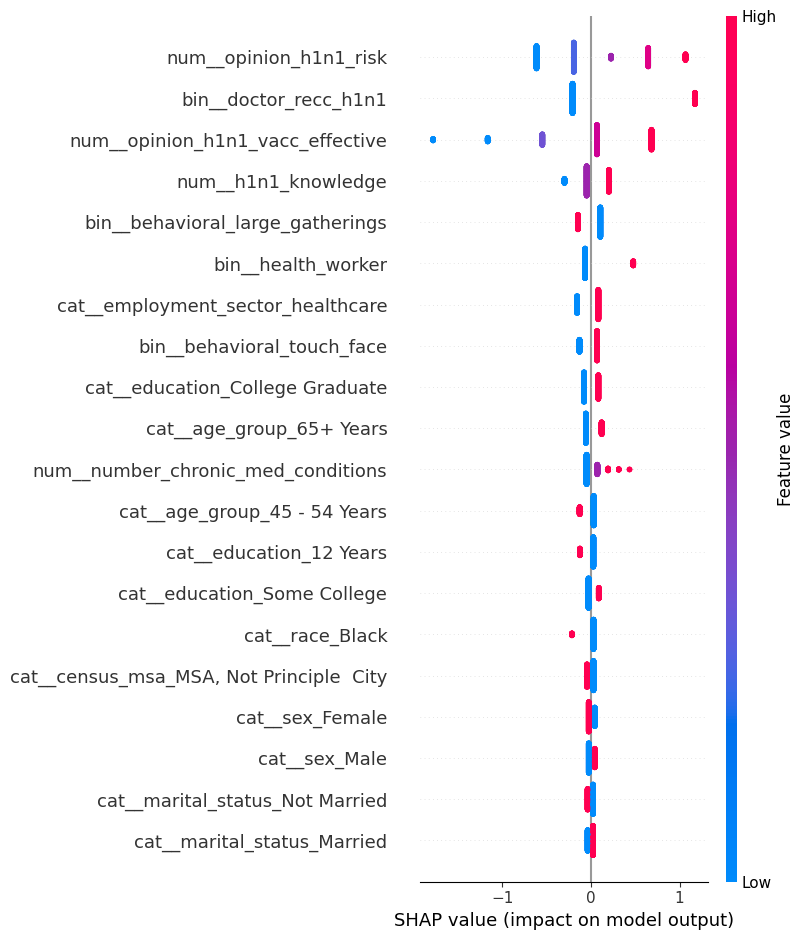

In [53]:

# Generate the SHAP summary plot
shap.summary_plot(
    shap_values,
    X_val_transformed_df,
    max_display=20,
    show=True
)


##SHAP Feature Importance Bar Plot


###46. SHAP Feature Importance – Mean Absolute SHAP Values

The SHAP feature importance bar plot ranks features according to their mean absolute SHAP values across all validation observations.

Unlike the SHAP summary plot, this visualisation focuses only on the magnitude of feature contributions and does not show their direction.

This helps us identify the features that have the greatest overall influence on the model's predictions.


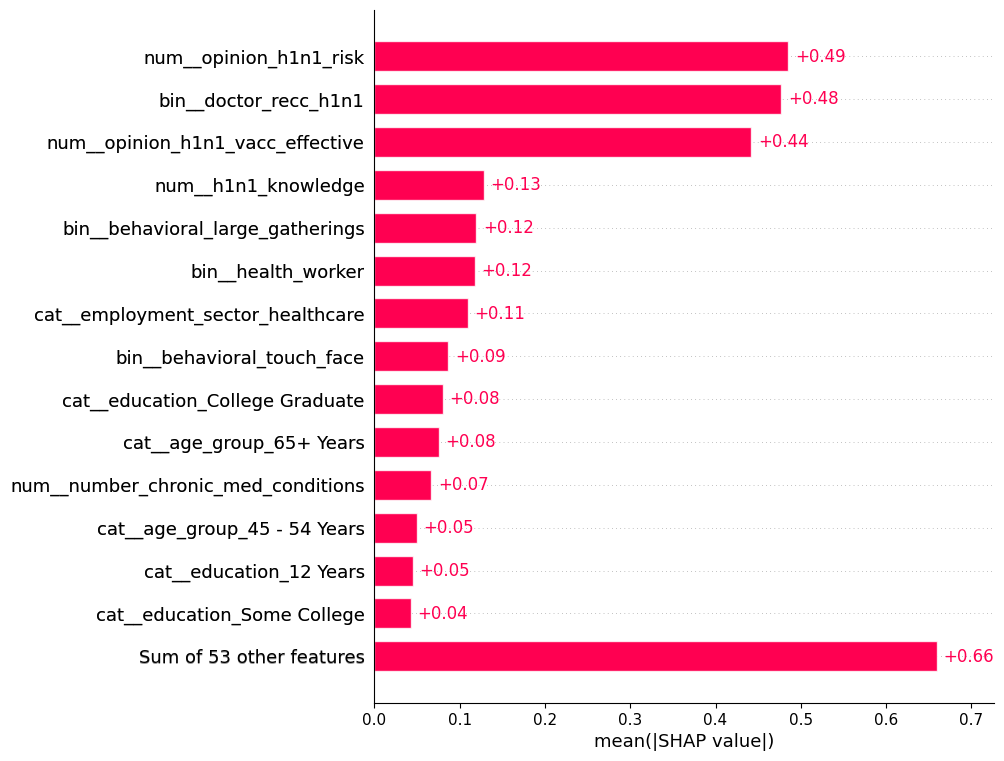

In [54]:

# Generate the SHAP feature importance bar plot
shap.plots.bar(
    shap_values,
    max_display=15
)


##SHAP Individual Prediction Explanation

Actual vaccine uptake: 0
Predicted acceptance probability: 0.3315


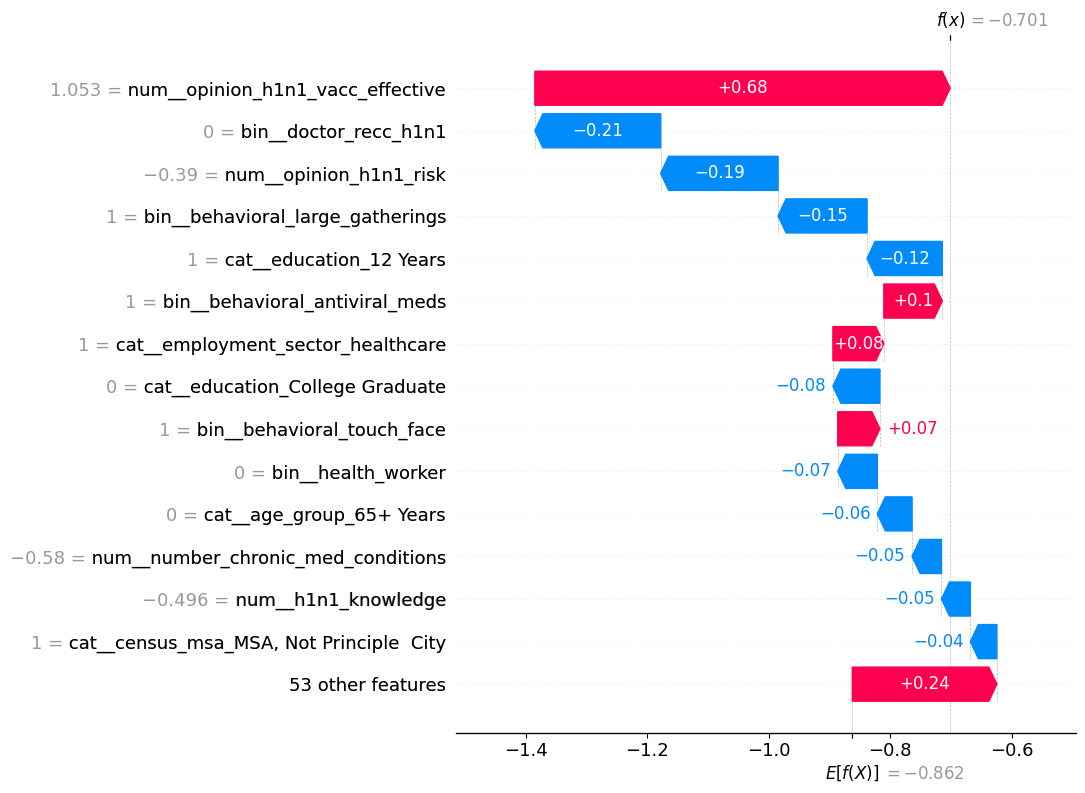

In [55]:

# Select one validation observation
sample_index = 0

# Display the actual outcome and predicted probability
sample_prediction = logistic_pipeline.predict_proba(
    X_val.iloc[[sample_index]]
)[0, 1]

sample_actual = y_val.iloc[sample_index]

print("Actual vaccine uptake:", sample_actual)
print("Predicted acceptance probability:", round(sample_prediction, 4))

# Generate the SHAP waterfall plot
shap.plots.waterfall(
    shap_values[sample_index],
    max_display=15
)


##Moving to LIME


###47. Introduction to LIME

LIME (Local Interpretable Model-agnostic Explanations) is an explainability technique that helps us understand individual machine learning predictions.

It works by generating small variations of an observation and examining how the trained model responds to those variations.

LIME then fits a simple interpretable model around the selected observation to identify the features that contribute positively or negatively to the prediction.

In this project, we use LIME to explain individual predictions made by our tuned Logistic Regression model.



###48. Preparing the LIME Explainer

We prepare the LIME Tabular Explainer using the original training dataset.

We use the original 29 features rather than the 67 transformed features so that the explanations are easier to interpret.

The prediction function supplied to LIME applies the existing Logistic Regression pipeline, including all preprocessing steps, before generating class probabilities.


In [56]:

# Transform the training data using the existing preprocessor
X_train_transformed = preprocessor_xai.transform(X_train)

# Convert sparse matrices to dense arrays if necessary
if hasattr(X_train_transformed, "toarray"):
    X_train_transformed = X_train_transformed.toarray()

# Identify binary and one-hot encoded categorical features
categorical_indices = [
    i for i, name in enumerate(feature_names)
    if name.startswith(("bin__", "cat__"))
]

# Define categorical feature values
categorical_names = {
    i: [0, 1] for i in categorical_indices
}

# Create the LIME explainer
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_transformed,
    feature_names=feature_names.tolist(),
    class_names=["No H1N1 Vaccine", "H1N1 Vaccine"],
    categorical_features=categorical_indices,
    categorical_names=categorical_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Define prediction function for the fitted classifier
def predict_with_logistic_model(data):
    return logistic_classifier.predict_proba(data)

print("LIME explainer created successfully!")
print("Training observations:", X_train_transformed.shape[0])
print("Transformed features:", X_train_transformed.shape[1])
print("Categorical features:", len(categorical_indices))



LIME explainer created successfully!
Training observations: 3804
Transformed features: 67
Categorical features: 59


##LIME Individual Prediction Explanation

In [57]:

# Select the same validation observation used in SHAP
sample_index = 0

# Get the transformed observation
sample_instance = X_val_transformed_df.iloc[sample_index].to_numpy()

# Generate the LIME explanation
lime_exp = lime_explainer.explain_instance(
    data_row=sample_instance,
    predict_fn=predict_with_logistic_model,
    num_features=15,
    num_samples=5000
)

# Display the explanation
lime_exp.show_in_notebook(show_table=True)


##Comparing SHAP and LIME


###49. Comparison of SHAP and LIME Explanations

SHAP and LIME were used to explain the predictions of the tuned Logistic Regression model.

SHAP calculates feature contributions based on Shapley values, while LIME approximates the model locally using an interpretable surrogate model.

Both techniques identified similar influential factors for the selected respondent, particularly the opinion on vaccine effectiveness, doctor recommendation, and perceived H1N1 risk.

The agreement between these explanations provides additional insight into the factors influencing this individual prediction. However, the contribution values are not directly comparable because the two methods use different explanation approaches and scales.



###50. Overall Explainable AI Findings

In this project, SHAP and LIME were used to interpret the predictions generated by our tuned Logistic Regression model.

SHAP provided global and individual explanations, while LIME helped us understand the factors influencing a specific respondent's prediction.

The global SHAP analysis identified the following important features:

- H1N1 risk opinion
- Doctor recommendation for H1N1 vaccination
- Opinion on H1N1 vaccine effectiveness
- H1N1 knowledge
- Behavioural factors such as attending large gatherings

The SHAP individual explanation showed how different features contributed positively or negatively to a respondent's predicted vaccine acceptance.

LIME was then applied to the same respondent. It identified similar influential factors, including vaccine effectiveness opinion, doctor recommendation, and perceived H1N1 risk.

The agreement between SHAP and LIME for the selected respondent provides additional confidence in our interpretation of that prediction.

###51. Conclusion

The XAI analysis helped us understand how our Logistic Regression model makes H1N1 vaccine uptake predictions.

The results indicate that respondents' opinions about H1N1 risk, vaccine effectiveness, and doctor recommendations are among the most influential factors in the model's predictions.

SHAP provided an understanding of global feature importance and individual prediction contributions, while LIME offered a complementary local explanation.

By combining both techniques, we improved the interpretability and transparency of our machine learning solution.

These explanations describe patterns learned by the model and should not be interpreted as evidence of causal relationships.


In [58]:
lime_validation_categorical_check = {}

for index in categorical_indices:
    values = np.unique(X_val_transformed_df.iloc[:, index])
    lime_validation_categorical_check[feature_names[index]] = values.tolist()

for feature, values in lime_validation_categorical_check.items():
    print(f"{feature}: {values}")

all_validation_binary = all(
    set(values).issubset({0, 1})
    for values in lime_validation_categorical_check.values()
)

print("\nAll validation categorical features are binary:", all_validation_binary)

bin__behavioral_antiviral_meds: [0.0, 1.0]
bin__behavioral_avoidance: [0.0, 1.0]
bin__behavioral_face_mask: [0.0, 1.0]
bin__behavioral_wash_hands: [0.0, 1.0]
bin__behavioral_large_gatherings: [0.0, 1.0]
bin__behavioral_outside_home: [0.0, 1.0]
bin__behavioral_touch_face: [0.0, 1.0]
bin__doctor_recc_h1n1: [0.0, 1.0]
bin__child_under_6_months: [0.0, 1.0]
bin__health_worker: [0.0, 1.0]
bin__health_insurance: [0.0, 1.0]
cat__age_group_18 - 34 Years: [0.0, 1.0]
cat__age_group_35 - 44 Years: [0.0, 1.0]
cat__age_group_45 - 54 Years: [0.0, 1.0]
cat__age_group_55 - 64 Years: [0.0, 1.0]
cat__age_group_65+ Years: [0.0, 1.0]
cat__education_12 Years: [0.0, 1.0]
cat__education_< 12 Years: [0.0, 1.0]
cat__education_College Graduate: [0.0, 1.0]
cat__education_Some College: [0.0, 1.0]
cat__race_Black: [0.0, 1.0]
cat__race_Hispanic: [0.0, 1.0]
cat__race_Other or Multiple: [0.0, 1.0]
cat__race_White: [0.0, 1.0]
cat__sex_Female: [0.0, 1.0]
cat__sex_Male: [0.0, 1.0]
cat__income_poverty_<= $75,000, Above Po